Script to automatically align volumetric scape data to a muscle reference map by using the accessory heart muscles.

Requires first manually labelled the accessory heart muscles in the scape video. Note: do this when the muscle is lit up but not when it is contracted, as it distorts its shape.

Steps:
- Load manual rois 
- Load max projection for matching data
- asign manual rois an identity (RF, LF, etc.) - remember right is on left when looking at legs
- Load reference labels (for acc-heart-muscles but also all selected muscles)
- get centroid of both manual and referece
- scale, rotate and shift reference to match manual - how does it look? Compare selected muscles to max projection
- if not great, try stretching

### Load all relevant data

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance

from scape_utils import load_napari_rois, load_voxel_size, load_aspect_ratio_YX, load_proj

import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging/referenceMaps')))
from webknossos import load_labels

In [2]:
# set paths to data and reference map labels:
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_run2'
acc_heart_path = scape_path / 'accessory_heart_muscles_rois.nrrd'

reference_path = Path('/mnt/labserver/data/MA/CT_scans_PIXE/2026-06-16_Webknossos_muscle_leg_tracing_pupa_annotations/Front Right Leg muscles in pupa')
labels_path = reference_path / 'Labels'
selected_path = reference_path / 'meshes-selected'

In [3]:
# Get std image for scape data (and aspect_ratio for plotting)
std = load_proj(scape_path, 'std_image')
voxel_sizes = load_voxel_size(scape_path)
axes_order = list(voxel_sizes.keys())

aspect_ratio = [
    voxel_sizes[others[0]] / voxel_sizes[others[1]]
    for i, element in enumerate(axes_order)
    for others in [axes_order[:i] + axes_order[i+1:]]
]

In [4]:
# Load manual rois for accessory heart muscles (labels)
acc_heart_manual = load_napari_rois(acc_heart_path)
acc_heart_manual_id = {'RM': 1, 'RF': 2, 'LF': 3, 'LM': 4}

In [5]:
# Load reference labels
labels, id_to_name = load_labels(labels_path) # takes about 1 min
# webknossos labels are indexed (x,y,z); reorder to match manual (z,y,x) axes
# (must reverse axis order, not permute (1,2,0) which gives (y,z,x)):
labels = np.transpose(labels, (2, 1, 0))
# two axes are inverted (point reflection) - so reverse
labels = labels[::-1, ::-1, :]

# select accessory heart muscles
acc_heart_ref_id = {name[:2]: id for id, name in id_to_name.items() if 'heart' in name and 'p1' in name}
# find the selected muscles (all files in the selected_path folder)
stl_list = list(selected_path.glob('*.stl'))
selected_muscles = {k: v for k, v in (p.stem.rsplit('-', 1) for p in stl_list)}

### Align centroids

In [6]:
# get centroids for each accessory heart muscle in the reference and manual rois
centroids_manual = {}
centroids_ref = {}

for leg, id in acc_heart_manual_id.items():

    # manual centroids
    mask_manual = acc_heart_manual == id
    coords_manual = np.argwhere(mask_manual)
    centroids_manual[leg] = coords_manual.mean(axis=0)

    # correct manual centroids for aspect ratio
    centroids_manual[leg] = centroids_manual[leg] * list(voxel_sizes[ax] for ax in axes_order)

    # reference centroids
    ref_id = acc_heart_ref_id[leg]
    mask_ref = labels == ref_id
    coords_ref = np.argwhere(mask_ref)
    centroids_ref[leg] = coords_ref.mean(axis=0)

    del mask_manual, coords_manual, mask_ref, coords_ref


### Fit similarity transform

In [7]:
def fit_similarity_transform(source_points, target_points):
    """
    Fits a rigid + uniform scale transform mapping source points onto
    target points, using Umeyama's closed-form least-squares algorithm.

    Solves for the rotation `R`, scale `s`, and translation `t` that
    minimize `sum(||s * R @ source_i + t - target_i||**2)` over all
    corresponding point pairs. Points must already be in correspondence
    (`source_points[i]` matches `target_points[i]`).

    Parameters
    ----------
    source_points : (N, 3) array
        Points to be transformed (here: reference centroids).

    target_points : (N, 3) array
        Points to align to (here: manual centroids, in physical units).

    Returns
    -------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.
    """
    source = np.asarray(source_points, dtype=float)
    target = np.asarray(target_points, dtype=float)
    n_points = source.shape[0]

    mean_source = source.mean(axis=0)
    mean_target = target.mean(axis=0)
    source_centered = source - mean_source
    target_centered = target - mean_target

    covariance = (target_centered.T @ source_centered) / n_points
    U, singular_values, Vt = np.linalg.svd(covariance)

    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[-1, -1] = -1

    R = U @ S @ Vt
    source_variance = np.sum(source_centered ** 2) / n_points
    scale = np.sum(singular_values * np.diag(S)) / source_variance
    t = mean_target - scale * (R @ mean_source)

    return R, scale, t

In [8]:
def build_homogeneous_transform(R, scale, t):
    """
    Assembles a rotation, scale, and translation into a 4x4 homogeneous
    transform mapping `x` to `scale * R @ x + t`.

    Parameters
    ----------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.

    Returns
    -------
    (4, 4) array
        Homogeneous transform matrix.
    """
    T = np.eye(4)
    T[:3, :3] = scale * R
    T[:3, 3] = t
    return T

In [9]:
# fixed correspondence order so the reference/manual point arrays line up
# by leg identity, not by dict iteration order
leg_order = ['RM', 'RF', 'LF', 'LM']
ref_points = np.array([centroids_ref[leg] for leg in leg_order])
manual_points = np.array([centroids_manual[leg] for leg in leg_order])

R, scale, t = fit_similarity_transform(ref_points, manual_points)
T_forward = build_homogeneous_transform(R, scale, t)

ref_points_aligned = {
    leg: scale * (R @ centroids_ref[leg]) + t for leg in leg_order
}
residuals = {
    leg: np.linalg.norm(ref_points_aligned[leg] - centroids_manual[leg])
    for leg in leg_order
}

print(f'Fitted scale (reference voxel units -> manual physical units): {scale:.4f}')
print(f'Per-landmark residual after fit (µm): {residuals}')

for leg_a, leg_b in [('RF', 'LF'), ('RM', 'LM')]:
    dist_manual = np.linalg.norm(centroids_manual[leg_a] - centroids_manual[leg_b])
    dist_aligned = np.linalg.norm(ref_points_aligned[leg_a] - ref_points_aligned[leg_b])
    print(f'{leg_a}-{leg_b} distance (µm) — manual: {dist_manual:.2f}, aligned reference: {dist_aligned:.2f}')

Fitted scale (reference voxel units -> manual physical units): 0.5965
Per-landmark residual after fit (µm): {'RM': np.float64(26.36554239409566), 'RF': np.float64(20.26413898587279), 'LF': np.float64(16.10381821065954), 'LM': np.float64(24.479580369439997)}
RF-LF distance (µm) — manual: 562.00, aligned reference: 567.04
RM-LM distance (µm) — manual: 572.65, aligned reference: 537.81


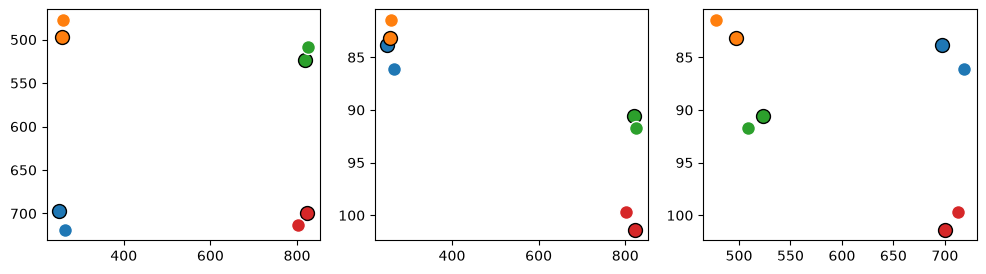

In [10]:
# QC: black-outlined = manual, white-outlined = fitted reference; same
# color = same leg identity. Overlapping same-colored pairs indicate a
# good fit.
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
fig, axs = plt.subplots(1, 3, figsize=[12, 3])
for ax_idx, ax_plot in enumerate(axs):
    axes = [n for n in [0, 1, 2] if n != ax_idx]
    for i, leg in enumerate(leg_order):
        manual_centroid = manual_points[i]
        aligned_centroid = ref_points_aligned[leg]
        ax_plot.plot(manual_centroid[axes[1]], manual_centroid[axes[0]], 'o', ms=10, mec='k', mfc=colors[i])
        ax_plot.plot(aligned_centroid[axes[1]], aligned_centroid[axes[0]], 'o', ms=10, mec='w', mfc=colors[i])
    ax_plot.invert_yaxis()

### Refine fit using principal axes

In [11]:
def get_principal_axis(labeled_array, label_id, voxel_size=None):
    """
    Computes the centroid, principal axis, and half-length of a labeled
    object via PCA.

    Parameters
    ----------
    labeled_array : ndarray
        Labeled voxel array to extract the object from.

    label_id : int
        Label id of the object.

    voxel_size : sequence of float or None
        Physical size per voxel, one value per axis, matching
        `labeled_array`'s own axis order. Coordinates are scaled by this
        before computing the covariance matrix, since PCA on raw
        anisotropic-index coordinates gives a physically wrong axis
        direction. Pass `None` for an isotropic array (no scaling).

    Returns
    -------
    centroid : (3,) array
        Centroid, in the same units as the (possibly scaled) coordinates.

    principal_axis : (3,) array
        Unit vector along the object's largest-variance direction.

    half_length : float
        One standard deviation of the object's extent along
        `principal_axis` (i.e. `sqrt` of the largest eigenvalue).
    """
    coords = np.argwhere(labeled_array == label_id).astype(float)
    if voxel_size is not None:
        coords = coords * np.asarray(voxel_size, dtype=float)

    centroid = coords.mean(axis=0)
    centered = coords - centroid
    covariance = np.cov(centered, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    principal_axis = eigenvectors[:, -1]
    half_length = np.sqrt(eigenvalues[-1])

    return centroid, principal_axis, half_length

In [12]:
def pair_axis_endpoints(ref_endpoint_plus, ref_endpoint_minus,
                         manual_endpoint_plus, manual_endpoint_minus, T_forward):
    """
    Resolves the arbitrary sign of a PCA principal axis between the
    reference and manual objects, using the current best-guess
    `T_forward` to decide which endpoint pairing is consistent.

    Parameters
    ----------
    ref_endpoint_plus : (3,) array
        Reference `centroid + half_length * axis`.

    ref_endpoint_minus : (3,) array
        Reference `centroid - half_length * axis`.

    manual_endpoint_plus : (3,) array
        Manual `centroid + half_length * axis`.

    manual_endpoint_minus : (3,) array
        Manual `centroid - half_length * axis`.

    T_forward : (4, 4) array
        Current best-guess homogeneous transform, reference -> manual.

    Returns
    -------
    tuple of ((3,) array, (3,) array)
        Two `(reference_endpoint, manual_endpoint)` pairs that correspond
        to the same real direction.
    """
    predicted_plus = T_forward[:3, :3] @ ref_endpoint_plus + T_forward[:3, 3]

    dist_same = np.linalg.norm(predicted_plus - manual_endpoint_plus)
    dist_swapped = np.linalg.norm(predicted_plus - manual_endpoint_minus)

    if dist_same <= dist_swapped:
        return (ref_endpoint_plus, manual_endpoint_plus), (ref_endpoint_minus, manual_endpoint_minus)
    return (ref_endpoint_plus, manual_endpoint_minus), (ref_endpoint_minus, manual_endpoint_plus)

In [13]:
# augment each leg's centroid with two axis-endpoint pseudo-landmarks
# (centroid +/- half_length * principal_axis), giving 12 correspondence
# points total instead of 4, then refit the same similarity transform
manual_voxel_size = [voxel_sizes[ax] for ax in axes_order]

ref_points_aug = []
manual_points_aug = []

for leg in leg_order:
    manual_centroid, manual_axis, manual_half_length = get_principal_axis(
        acc_heart_manual, acc_heart_manual_id[leg], voxel_size=manual_voxel_size
    )
    ref_centroid, ref_axis, ref_half_length = get_principal_axis(
        labels, acc_heart_ref_id[leg]
    )

    manual_endpoint_plus = manual_centroid + manual_half_length * manual_axis
    manual_endpoint_minus = manual_centroid - manual_half_length * manual_axis
    ref_endpoint_plus = ref_centroid + ref_half_length * ref_axis
    ref_endpoint_minus = ref_centroid - ref_half_length * ref_axis

    # T_forward here is still the centroid-only fit from the previous cell,
    # used only as a rough initial guess to resolve axis sign ambiguity
    pair_a, pair_b = pair_axis_endpoints(
        ref_endpoint_plus, ref_endpoint_minus,
        manual_endpoint_plus, manual_endpoint_minus,
        T_forward,
    )

    ref_points_aug.extend([centroids_ref[leg], pair_a[0], pair_b[0]])
    manual_points_aug.extend([centroids_manual[leg], pair_a[1], pair_b[1]])

ref_points_aug = np.array(ref_points_aug)
manual_points_aug = np.array(manual_points_aug)

R, scale, t = fit_similarity_transform(ref_points_aug, manual_points_aug)
T_forward = build_homogeneous_transform(R, scale, t)

ref_points_aligned = {
    leg: scale * (R @ centroids_ref[leg]) + t for leg in leg_order
}
residuals = {
    leg: np.linalg.norm(ref_points_aligned[leg] - centroids_manual[leg])
    for leg in leg_order
}

print(f'Refined fit using {len(ref_points_aug)} points (4 centroids + 2 axis-endpoints each)')
print(f'Fitted scale (reference voxel units -> manual physical units): {scale:.4f}')
print(f'Per-landmark residual after fit (µm): {residuals}')

for leg_a, leg_b in [('RF', 'LF'), ('RM', 'LM')]:
    dist_manual = np.linalg.norm(centroids_manual[leg_a] - centroids_manual[leg_b])
    dist_aligned = np.linalg.norm(ref_points_aligned[leg_a] - ref_points_aligned[leg_b])
    print(f'{leg_a}-{leg_b} distance (µm) — manual: {dist_manual:.2f}, aligned reference: {dist_aligned:.2f}')

Refined fit using 12 points (4 centroids + 2 axis-endpoints each)
Fitted scale (reference voxel units -> manual physical units): 0.5942
Per-landmark residual after fit (µm): {'RM': np.float64(26.549472776978842), 'RF': np.float64(19.885116276456102), 'LF': np.float64(15.396050036997698), 'LM': np.float64(25.1400194073386)}
RF-LF distance (µm) — manual: 562.00, aligned reference: 564.92
RM-LM distance (µm) — manual: 572.65, aligned reference: 535.80


### Try a full affine fit (independent per-axis scale)

In [14]:
def fit_affine_transform(source_points, target_points):
    """
    Fits a full affine transform (3x3 linear map `A`, translation `t`)
    mapping source points onto target points via ordinary least squares.

    Unlike `fit_similarity_transform`, `A` is not constrained to be
    `scale * R` for a proper rotation `R` — it allows independent scale
    per axis (and shear), at the cost of no longer being guaranteed to
    preserve shape. Solves for `A`, `t` minimizing
    `sum(||A @ source_i + t - target_i||**2)`.

    Parameters
    ----------
    source_points : (N, 3) array
        Points to be transformed.

    target_points : (N, 3) array
        Points to align to.

    Returns
    -------
    A : (3, 3) array
        Linear map (rotation + independent per-axis scale + shear).

    t : (3,) array
        Translation vector.
    """
    source = np.asarray(source_points, dtype=float)
    target = np.asarray(target_points, dtype=float)

    design = np.hstack([source, np.ones((source.shape[0], 1))])
    solution, _, _, _ = np.linalg.lstsq(design, target, rcond=None)

    A = solution[:3, :].T
    t = solution[3, :]

    return A, t

In [15]:
# diagnostic only: does allowing independent per-axis scale (12 DOF)
# instead of one global scale (7 DOF) actually reduce residual on the
# original 4 centroids? T_forward (used by the warp cells below) is left
# as the similarity fit unless this shows a clear improvement.
A, t_affine = fit_affine_transform(ref_points_aug, manual_points_aug)
T_forward_affine = build_homogeneous_transform(A, 1.0, t_affine)

ref_points_aligned_affine = {
    leg: A @ centroids_ref[leg] + t_affine for leg in leg_order
}
residuals_affine = {
    leg: np.linalg.norm(ref_points_aligned_affine[leg] - centroids_manual[leg])
    for leg in leg_order
}

singular_values = np.linalg.svd(A, compute_uv=False)

print(f'Affine-fit per-landmark residual (µm): {residuals_affine}')
print(f'Similarity-fit per-landmark residual (µm), for comparison: {residuals}')
print(f'Singular values of A (per-axis stretch factors): {singular_values}')
print(f'Ratio of largest to smallest singular value (1.0 = isotropic scale): {singular_values[0] / singular_values[-1]:.4f}')

for leg_a, leg_b in [('RF', 'LF'), ('RM', 'LM')]:
    dist_manual = np.linalg.norm(centroids_manual[leg_a] - centroids_manual[leg_b])
    dist_aligned = np.linalg.norm(ref_points_aligned_affine[leg_a] - ref_points_aligned_affine[leg_b])
    print(f'{leg_a}-{leg_b} distance (µm) — manual: {dist_manual:.2f}, affine-aligned reference: {dist_aligned:.2f}')

Affine-fit per-landmark residual (µm): {'RM': np.float64(9.76216464707728), 'RF': np.float64(8.430539424287844), 'LF': np.float64(8.909635624265459), 'LM': np.float64(10.2323974230388)}
Similarity-fit per-landmark residual (µm), for comparison: {'RM': np.float64(26.549472776978842), 'RF': np.float64(19.885116276456102), 'LF': np.float64(15.396050036997698), 'LM': np.float64(25.1400194073386)}
Singular values of A (per-axis stretch factors): [2.22930016 0.59202903 0.0143852 ]
Ratio of largest to smallest singular value (1.0 = isotropic scale): 154.9718
RF-LF distance (µm) — manual: 562.00, affine-aligned reference: 577.96
RM-LM distance (µm) — manual: 572.65, affine-aligned reference: 553.85


### Use all 3 principal axes per muscle (not just the longest)

In [16]:
def get_principal_axes(labeled_array, label_id, voxel_size=None):
    """
    Computes the centroid and all three principal axes/half-lengths of a
    labeled object via PCA, sorted by decreasing variance.

    The single-axis version (`get_principal_axis`) only used the longest
    axis, which turned out to add little independent 3D information since
    the 4 muscles' centroids and long axes are close to coplanar - an
    unconstrained affine fit on that data was ill-conditioned along the
    thin/missing direction. Using all 3 axes gives each muscle's own local
    3D shape (including its thinnest direction) a chance to constrain that.

    Parameters
    ----------
    labeled_array : ndarray
        Labeled voxel array to extract the object from.

    label_id : int
        Label id of the object.

    voxel_size : sequence of float or None
        Physical size per voxel, one value per axis, matching
        `labeled_array`'s own axis order. Coordinates are scaled by this
        before computing the covariance matrix, since PCA on raw
        anisotropic-index coordinates gives a physically wrong axis
        direction. Pass `None` for an isotropic array (no scaling).

    Returns
    -------
    centroid : (3,) array
        Centroid, in the same units as the (possibly scaled) coordinates.

    axes : (3, 3) array
        Unit eigenvectors as columns, ordered from largest to smallest
        variance (`axes[:, 0]` is the long axis, `axes[:, 2]` the
        thinnest).

    half_lengths : (3,) array
        One standard deviation of the object's extent along each axis
        (`sqrt` of the corresponding eigenvalue), same ordering.
    """
    coords = np.argwhere(labeled_array == label_id).astype(float)
    if voxel_size is not None:
        coords = coords * np.asarray(voxel_size, dtype=float)

    centroid = coords.mean(axis=0)
    centered = coords - centroid
    covariance = np.cov(centered, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    axes = eigenvectors[:, order]
    half_lengths = np.sqrt(eigenvalues[order])

    return centroid, axes, half_lengths

In [17]:
# build a richer correspondence set: centroid + all 3 axis endpoints per
# leg (7 points/leg x 4 legs = 28 points), then check whether the affine
# fit's singular values become well-conditioned (i.e. whether the earlier
# near-degenerate collapse was really due to missing 3D shape information)
ref_points_full = []
manual_points_full = []

for leg in leg_order:
    manual_centroid, manual_axes, manual_half_lengths = get_principal_axes(
        acc_heart_manual, acc_heart_manual_id[leg], voxel_size=manual_voxel_size
    )
    ref_centroid, ref_axes, ref_half_lengths = get_principal_axes(
        labels, acc_heart_ref_id[leg]
    )

    ref_points_full.append(centroids_ref[leg])
    manual_points_full.append(centroids_manual[leg])

    for axis_idx in range(3):
        manual_axis = manual_axes[:, axis_idx]
        manual_half_length = manual_half_lengths[axis_idx]
        ref_axis = ref_axes[:, axis_idx]
        ref_half_length = ref_half_lengths[axis_idx]

        manual_endpoint_plus = manual_centroid + manual_half_length * manual_axis
        manual_endpoint_minus = manual_centroid - manual_half_length * manual_axis
        ref_endpoint_plus = ref_centroid + ref_half_length * ref_axis
        ref_endpoint_minus = ref_centroid - ref_half_length * ref_axis

        # T_forward here is still the best similarity fit so far, used only
        # as a rough initial guess to resolve axis sign ambiguity
        pair_a, pair_b = pair_axis_endpoints(
            ref_endpoint_plus, ref_endpoint_minus,
            manual_endpoint_plus, manual_endpoint_minus,
            T_forward,
        )
        ref_points_full.extend([pair_a[0], pair_b[0]])
        manual_points_full.extend([pair_a[1], pair_b[1]])

ref_points_full = np.array(ref_points_full)
manual_points_full = np.array(manual_points_full)

# fit both models on the richer point set, without overwriting T_forward -
# this stays diagnostic until we know which (if either) is trustworthy
R_full, scale_full, t_full = fit_similarity_transform(ref_points_full, manual_points_full)
ref_points_aligned_full_sim = {
    leg: scale_full * (R_full @ centroids_ref[leg]) + t_full for leg in leg_order
}
residuals_full_sim = {
    leg: np.linalg.norm(ref_points_aligned_full_sim[leg] - centroids_manual[leg])
    for leg in leg_order
}

A_full, t_affine_full = fit_affine_transform(ref_points_full, manual_points_full)
ref_points_aligned_full_affine = {
    leg: A_full @ centroids_ref[leg] + t_affine_full for leg in leg_order
}
residuals_full_affine = {
    leg: np.linalg.norm(ref_points_aligned_full_affine[leg] - centroids_manual[leg])
    for leg in leg_order
}
singular_values_full = np.linalg.svd(A_full, compute_uv=False)

print(f'Built {len(ref_points_full)} correspondence points (4 centroids + 3 axes x 2 endpoints each)')
print(f'Similarity-fit (28 pts) residual (µm): {residuals_full_sim}')
print(f'Affine-fit (28 pts) residual (µm): {residuals_full_affine}')
print(f'Affine-fit (28 pts) singular values of A: {singular_values_full}')
print(f'Ratio largest/smallest singular value (was 154.97 with 1 axis only): {singular_values_full[0] / singular_values_full[-1]:.4f}')

Built 28 correspondence points (4 centroids + 3 axes x 2 endpoints each)
Similarity-fit (28 pts) residual (µm): {'RM': np.float64(26.438984024509754), 'RF': np.float64(20.097048430451736), 'LF': np.float64(15.795951286912894), 'LM': np.float64(24.755565188528617)}
Affine-fit (28 pts) residual (µm): {'RM': np.float64(9.356341521823207), 'RF': np.float64(8.484656987901545), 'LF': np.float64(9.896668106067), 'LM': np.float64(10.765638188779112)}
Affine-fit (28 pts) singular values of A: [1.01624268 0.56927887 0.2594364 ]
Ratio largest/smallest singular value (was 154.97 with 1 axis only): 3.9171


### Warp reference volume onto manual grid

In [18]:
from scipy.ndimage import affine_transform


def warp_labels_to_manual_grid(source_volume, T_forward, target_shape,
                                source_voxel_size=(1.0, 1.0, 1.0),
                                target_voxel_size=(1.0, 1.0, 1.0)):
    """
    Resamples a labeled voxel volume onto a differently-spaced target grid,
    using a rigid + uniform scale transform fit on physical-space points.

    All coordinates and voxel sizes are in array-axis order (matching
    `source_volume`'s and `target_shape`'s own axis order, e.g. (z, y, x)) —
    since `T_forward` was fit directly on `np.argwhere`-derived centroids in
    that same order, no physical (x, y, z) <-> array-index permutation is
    needed here.

    Parameters
    ----------
    source_volume : ndarray
        Labeled array to resample from (e.g. the reference `labels`
        volume).

    T_forward : (4, 4) array
        Homogeneous transform mapping source physical coordinates to
        target physical coordinates (see `build_homogeneous_transform`).

    target_shape : tuple of int
        Output array shape, matching the target grid (e.g.
        `acc_heart_manual.shape`).

    source_voxel_size : tuple of float
        Physical size per voxel of `source_volume`, one value per axis.

    target_voxel_size : tuple of float
        Physical size per voxel of the output grid, one value per axis.

    Returns
    -------
    ndarray
        `source_volume` resampled onto the target grid, with label IDs
        preserved via nearest-neighbor interpolation.
    """
    S_source = np.diag([*source_voxel_size, 1.0])
    S_target = np.diag([*target_voxel_size, 1.0])

    # maps target voxel indices to source voxel indices (pull mapping,
    # as required by affine_transform)
    T_voxel = np.linalg.inv(S_source) @ np.linalg.inv(T_forward) @ S_target

    return affine_transform(
        source_volume,
        matrix=T_voxel[:3, :3],
        offset=T_voxel[:3, 3],
        output_shape=target_shape,
        order=0,
        mode='constant',
        cval=0,
    )

In [19]:
target_voxel_size = tuple(voxel_sizes[ax] for ax in axes_order)

labels_aligned = warp_labels_to_manual_grid(
    labels, T_forward,
    target_shape=acc_heart_manual.shape,
    source_voxel_size=(1.0, 1.0, 1.0),
    target_voxel_size=target_voxel_size,
)

print('Reference non-zero voxels:', np.count_nonzero(labels))
print('Aligned non-zero voxels:', np.count_nonzero(labels_aligned))
print('Unique labels preserved:', np.unique(labels_aligned))

Reference non-zero voxels: 68353692
Aligned non-zero voxels: 2424945
Unique labels preserved: [ 0  1  2  3  4  5  6  7  8  9 10 11 13 14 15 16 17 18 19 20 21 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 46 47 48 49 50
 51 52 53 54 55 56 57 58 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75
 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]


### Visual QC: compare aligned reference to SCAPE data

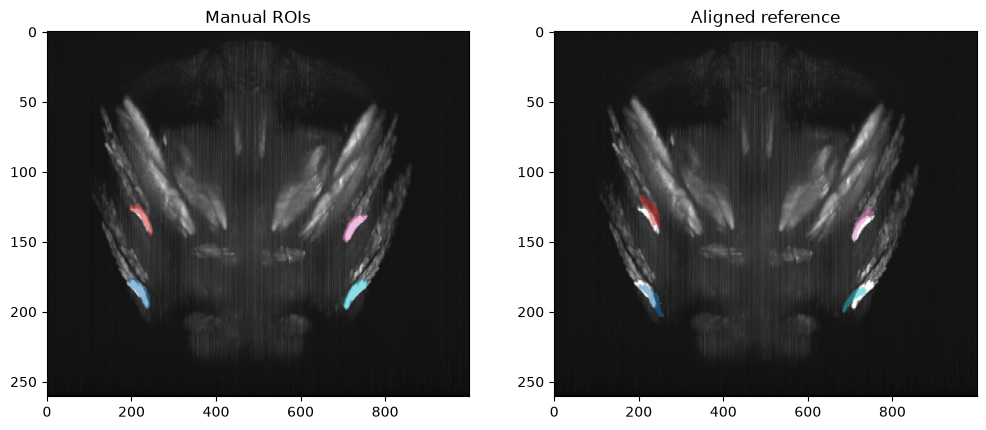

In [20]:
# relabel the aligned reference's heart-muscle IDs to match acc_heart_manual_id,
# so the two overlays share the same color mapping
ax_proj = 0  # project along z, matching how std/acc_heart_manual are viewed above

# std is a 3D per-voxel temporal-std volume, not a precomputed 2D
# projection, so it needs to be projected too before display
std_proj = np.max(std, axis=ax_proj)

acc_heart_aligned = np.zeros_like(labels_aligned, dtype=np.uint8)
for leg, ref_id in acc_heart_ref_id.items():
    acc_heart_aligned[labels_aligned == ref_id] = acc_heart_manual_id[leg]

fig, axs = plt.subplots(1, 2, figsize=[12, 6])
for ax_plot, volume, title in zip(
    axs, (acc_heart_manual, acc_heart_aligned), ('Manual ROIs', 'Aligned reference')
):
    ax_plot.imshow(std_proj, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=80)
    overlay = np.ma.masked_equal(np.max(volume, axis=ax_proj), 0)
    ax_plot.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='tab10', alpha=0.5, vmin=1, vmax=4)
    ax_plot.set_title(title)

Text(0.5, 1.0, 'All selected muscles, aligned reference')

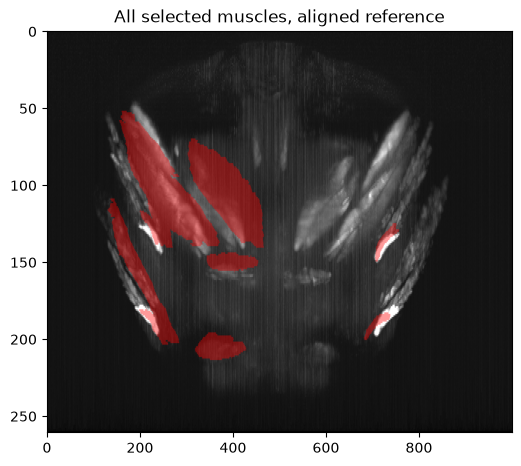

In [23]:
# broader sanity check: do all the selected leg muscles (not just the
# heart-muscle landmarks used to fit the transform) look anatomically
# plausible against the SCAPE std projection?
selected_ids = {int(muscle_id) for muscle_id in selected_muscles.values()}
selected_mask = np.isin(labels_aligned, list(selected_ids))

plt.figure(figsize=[6, 6])
plt.imshow(std_proj, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=80)
overlay = np.ma.masked_equal(np.max(selected_mask, axis=ax_proj), 0)
plt.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='autumn', alpha=0.4)
plt.title('All selected muscles, aligned reference')

# TESTING / PLOTTING